In [ ]:
# 05 — Energy Simulation
Goal: Use our 60-minute forecast to simulate a "Smart Cooling" strategy vs a "Dumb Cooling" strategy.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error

# --- STEP 1: Re-load the data and re-train the 60-min model (since this is a new notebook) ---
aau = pd.read_csv("../data/raw/AAU_temperature_and_power_use.csv")
aau['Time [Date/Time]'] = pd.to_datetime(aau['Time [Date/Time]'])

cols_to_keep = ['Time [Date/Time]', 'Temperature mod 1 ch 1',
                'Power Ch 1 (W)', 'Power Ch 2 (W)', 'Power Ch 3 (W)']
df = aau[cols_to_keep].copy()
df = df.set_index('Time [Date/Time]').resample('1min').mean().reset_index()

df = df.rename(columns={
    'Time [Date/Time]': 'time',
    'Temperature mod 1 ch 1': 'temp',
    'Power Ch 1 (W)': 'power_1',
    'Power Ch 2 (W)': 'power_2',
    'Power Ch 3 (W)': 'power_3'
})

df['hour'] = df['time'].dt.hour
df['minute'] = df['time'].dt.minute
df['regime'] = (df['time'] >= '2024-09-28').astype(int)

df['temp_target_60m'] = df['temp'].shift(-60)
df['temp_lag_1m']  = df['temp'].shift(1)
df['temp_lag_5m']  = df['temp'].shift(5)
df['temp_lag_15m'] = df['temp'].shift(15)
df['temp_lag_60m'] = df['temp'].shift(60)
df['power_1_lag_1m'] = df['power_1'].shift(1)
df['power_1_lag_5m'] = df['power_1'].shift(5)
df['temp_rolling_mean_15m'] = df['temp'].rolling(window=15).mean()

df_clean = df.dropna().reset_index(drop=True)

split_date = pd.to_datetime('2024-09-28')
train = df_clean[df_clean['time'] < split_date]
test  = df_clean[df_clean['time'] >= split_date]

features = ['power_1', 'power_2', 'power_3', 'hour', 'minute', 'regime',
            'temp_lag_1m', 'temp_lag_5m', 'temp_lag_15m', 'temp_lag_60m',
            'power_1_lag_1m', 'power_1_lag_5m', 'temp_rolling_mean_15m']

X_train, y_train = train[features], train['temp_target_60m']
X_test, y_test = test[features], test['temp_target_60m']

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=7, random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# --- STEP 2: Now the simulation can run ---
results = pd.DataFrame({
    'time': test['time'].values,
    'actual_temp': y_test.values,
    'predicted_temp': predictions
})

# Dumb cooling: keep room at 22.0°C
baseline_energy = (results['actual_temp'] - 22.0).clip(lower=1.0)

# Smart cooling: if we predict temp will drop, relax the target by +0.5°C
smart_energy = []
for i in range(len(results)):
    pred = results['predicted_temp'].iloc[i]
    actual = results['actual_temp'].iloc[i]
    if pred < actual:
        current_target = 22.5   # relaxed — less cooling
    else:
        current_target = 22.0
    energy = max(1.0, actual - current_target)
    smart_energy.append(energy)

results['baseline_energy'] = baseline_energy
results['smart_energy'] = smart_energy

total_baseline = results['baseline_energy'].sum()
total_smart    = results['smart_energy'].sum()
savings_percent = ((total_baseline - total_smart) / total_baseline) * 100

print(f"Total Baseline Energy: {total_baseline:.2f} units")
print(f"Total Smart Energy:    {total_smart:.2f} units")
print(f"Energy Saved:          {savings_percent:.2f}%")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001391 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2634
[LightGBM] [Info] Number of data points in the train set: 16202, number of used features: 12
[LightGBM] [Info] Start training from score 23.528528
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain

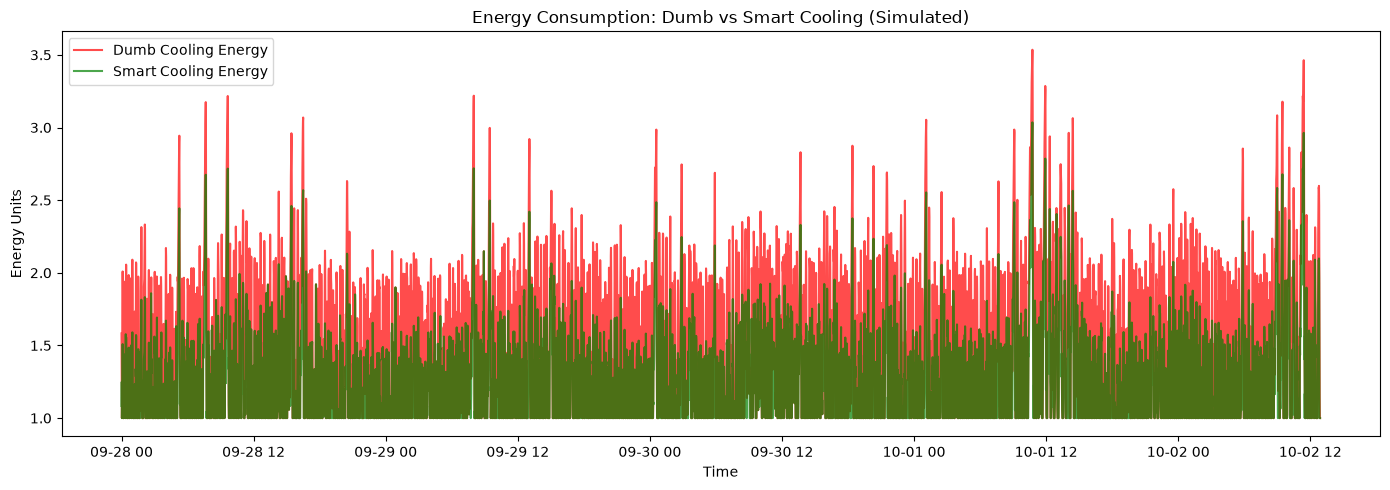

In [4]:
plt.figure(figsize=(14, 5))
plt.plot(results['time'], results['baseline_energy'], label='Dumb Cooling Energy', color='red', alpha=0.7)
plt.plot(results['time'], results['smart_energy'], label='Smart Cooling Energy', color='green', alpha=0.7)
plt.title('Energy Consumption: Dumb vs Smart Cooling (Simulated)')
plt.ylabel('Energy Units')
plt.xlabel('Time')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/figures/05_energy_savings.png', dpi=150)
plt.show()